In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Loading the Dataset

The employee attrition dataset is loaded using the pandas library.
Each row represents an employee and each column represents an employee
attribute such as age, department, job role, salary, overtime and attrition.

In [7]:
df = pd.read_csv("../../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [8]:
df.shape

(1470, 35)

In [9]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

## Initial Dataset Understanding

The dataset contains 1,470 employee records and 35 variables.
The dataset contains information related to employee demographics,
job characteristics, compensation, satisfaction, work-life balance
and employee attrition.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [11]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [12]:
df.duplicated().sum()

0

## Data Quality Check

The dataset contains no missing values and no duplicate rows.
Therefore, no missing-value imputation or duplicate-row removal is
required at this stage.

In [13]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [14]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [15]:
df["Department"].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

In [16]:
df["OverTime"].value_counts()

OverTime
No     1054
Yes     416
Name: count, dtype: int64

In [17]:
df["JobRole"].value_counts()


JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

In [18]:
attrition_count = df["Attrition"].value_counts()

print(attrition_count)

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [19]:
attrition_rate = (df["Attrition"] == "Yes").mean() * 100

print("Attrition Rate:", round(attrition_rate, 2), "%")

Attrition Rate: 16.12 %


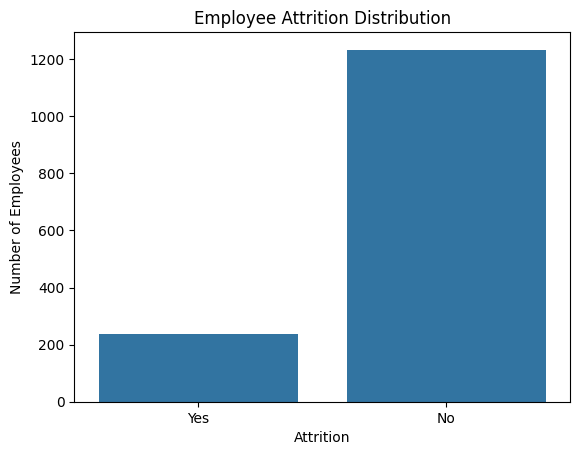

In [20]:
sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

In [21]:
df.columns.tolist()

['Age',
 'Attrition',
 'BusinessTravel',
 'DailyRate',
 'Department',
 'DistanceFromHome',
 'Education',
 'EducationField',
 'EmployeeCount',
 'EmployeeNumber',
 'EnvironmentSatisfaction',
 'Gender',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'Over18',
 'OverTime',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StandardHours',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

In [22]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [23]:
categorical_columns = df.select_dtypes(include=["object"]).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


C:\Users\Varun Kaushik\AppData\Local\Temp\ipykernel_29860\3028982148.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns


In [24]:
print("Number of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

Number of numerical columns: 26
Number of categorical columns: 9


In [25]:
for column in categorical_columns:
    print("\n", column)
    print(df[column].unique())


 Attrition
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

 BusinessTravel
<ArrowStringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

 Department
<ArrowStringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str

 EducationField
<ArrowStringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str

 Gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

 JobRole
<ArrowStringArray>
[          'Sales Executive',        'Research Scientist',
     'Laboratory Technician',    'Manufacturing Director',
 'Healthcare Representative',                   'Manager',
      'Sales Representative',         'Research Director',
           'Human Resources']
Length: 9, dtype: str

 MaritalStatus
<ArrowStringArray>
['Single', 'Married', 'Divorced']
Length: 3, dtype: str

 Over18
<ArrowStringArray>
['Y']
Length: 1, dtype: str


In [26]:
for column in numerical_columns:
    print("\n", column)
    print("Min:", df[column].min())
    print("Max:", df[column].max())


 Age
Min: 18
Max: 60

 DailyRate
Min: 102
Max: 1499

 DistanceFromHome
Min: 1
Max: 29

 Education
Min: 1
Max: 5

 EmployeeCount
Min: 1
Max: 1

 EmployeeNumber
Min: 1
Max: 2068

 EnvironmentSatisfaction
Min: 1
Max: 4

 HourlyRate
Min: 30
Max: 100

 JobInvolvement
Min: 1
Max: 4

 JobLevel
Min: 1
Max: 5

 JobSatisfaction
Min: 1
Max: 4

 MonthlyIncome
Min: 1009
Max: 19999

 MonthlyRate
Min: 2094
Max: 26999

 NumCompaniesWorked
Min: 0
Max: 9

 PercentSalaryHike
Min: 11
Max: 25

 PerformanceRating
Min: 3
Max: 4

 RelationshipSatisfaction
Min: 1
Max: 4

 StandardHours
Min: 80
Max: 80

 StockOptionLevel
Min: 0
Max: 3

 TotalWorkingYears
Min: 0
Max: 40

 TrainingTimesLastYear
Min: 0
Max: 6

 WorkLifeBalance
Min: 1
Max: 4

 YearsAtCompany
Min: 0
Max: 40

 YearsInCurrentRole
Min: 0
Max: 18

 YearsSinceLastPromotion
Min: 0
Max: 15

 YearsWithCurrManager
Min: 0
Max: 17


In [27]:
data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

data_dictionary["Unique Values"] = [
    df[column].nunique() for column in df.columns
]

data_dictionary["Missing Values"] = [
    df[column].isnull().sum() for column in df.columns
]

data_dictionary

,Column,Data Type,Unique Values,Missing Values
0,Age,int64,43,0
1,Attrition,str,2,0
2,BusinessTravel,str,3,0
3,DailyRate,int64,886,0
4,Department,str,3,0
5,DistanceFromHome,int64,29,0
6,Education,int64,5,0
7,EducationField,str,6,0
8,EmployeeCount,int64,1,0
9,EmployeeNumber,int64,1470,0


In [28]:
constant_columns = []

for column in df.columns:
    if df[column].nunique() == 1:
        constant_columns.append(column)

print("Constant columns:", constant_columns)

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


In [29]:
print("EmployeeNumber unique values:", df["EmployeeNumber"].nunique())
print("Total rows:", len(df))

EmployeeNumber unique values: 1470
Total rows: 1470


In [30]:
df_clean = df.copy()
df_clean = df_clean.drop(
    columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"]
)
df_clean.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [31]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   str  
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   str  
 14  JobSatisfaction           1470 non-null   int64
 15

In [32]:
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())

Missing values: 0
Duplicates: 0


In [33]:
for column in df_clean.select_dtypes(include=["int64", "float64"]).columns:
    print(column, "→ Min:", df_clean[column].min(), 
          "| Max:", df_clean[column].max())

Age → Min: 18 | Max: 60
DailyRate → Min: 102 | Max: 1499
DistanceFromHome → Min: 1 | Max: 29
Education → Min: 1 | Max: 5
EnvironmentSatisfaction → Min: 1 | Max: 4
HourlyRate → Min: 30 | Max: 100
JobInvolvement → Min: 1 | Max: 4
JobLevel → Min: 1 | Max: 5
JobSatisfaction → Min: 1 | Max: 4
MonthlyIncome → Min: 1009 | Max: 19999
MonthlyRate → Min: 2094 | Max: 26999
NumCompaniesWorked → Min: 0 | Max: 9
PercentSalaryHike → Min: 11 | Max: 25
PerformanceRating → Min: 3 | Max: 4
RelationshipSatisfaction → Min: 1 | Max: 4
StockOptionLevel → Min: 0 | Max: 3
TotalWorkingYears → Min: 0 | Max: 40
TrainingTimesLastYear → Min: 0 | Max: 6
WorkLifeBalance → Min: 1 | Max: 4
YearsAtCompany → Min: 0 | Max: 40
YearsInCurrentRole → Min: 0 | Max: 18
YearsSinceLastPromotion → Min: 0 | Max: 15
YearsWithCurrManager → Min: 0 | Max: 17


In [34]:
rating_columns = [
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance"
]

for column in rating_columns:
    print(column, ":", sorted(df_clean[column].unique()))

EnvironmentSatisfaction : [1, 2, 3, 4]
JobInvolvement : [1, 2, 3, 4]
JobSatisfaction : [1, 2, 3, 4]
RelationshipSatisfaction : [1, 2, 3, 4]
WorkLifeBalance : [1, 2, 3, 4]


In [35]:
categorical_columns = df_clean.select_dtypes(include=["object"]).columns

for column in categorical_columns:
    print("\n", column)
    print(df_clean[column].unique())


 Attrition
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

 BusinessTravel
<ArrowStringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

 Department
<ArrowStringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str

 EducationField
<ArrowStringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str

 Gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

 JobRole
<ArrowStringArray>
[          'Sales Executive',        'Research Scientist',
     'Laboratory Technician',    'Manufacturing Director',
 'Healthcare Representative',                   'Manager',
      'Sales Representative',         'Research Director',
           'Human Resources']
Length: 9, dtype: str

 MaritalStatus
<ArrowStringArray>
['Single', 'Married', 'Divorced']
Length: 3, dtype: str

 OverTime
<ArrowStringArray>
['Yes', 'No']
Length: 2, d

C:\Users\Varun Kaushik\AppData\Local\Temp\ipykernel_29860\701029924.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(include=["object"]).columns


In [36]:
print(df_clean["Age"].describe())

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64


In [37]:
print(df_clean["MonthlyIncome"].describe())

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64


In [38]:
print(df_clean["YearsAtCompany"].describe())

count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64


In [39]:
print(df_clean["TotalWorkingYears"].describe())

count    1470.000000
mean       11.279592
std         7.780782
min         0.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        40.000000
Name: TotalWorkingYears, dtype: float64


In [40]:
invalid_years = df_clean[
    df_clean["YearsAtCompany"] > df_clean["TotalWorkingYears"]
]

print("Invalid records:", len(invalid_years))

Invalid records: 0


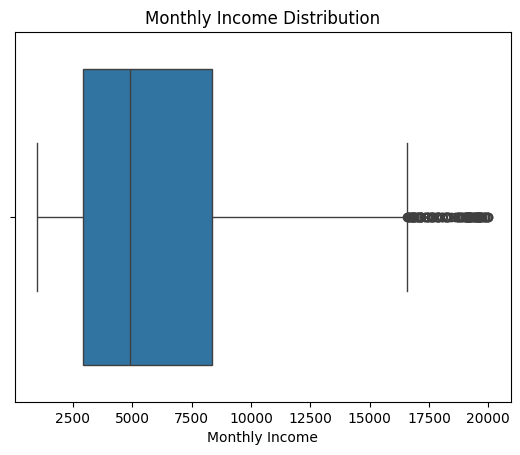

In [41]:
sns.boxplot(data=df_clean, x="MonthlyIncome")

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.show()

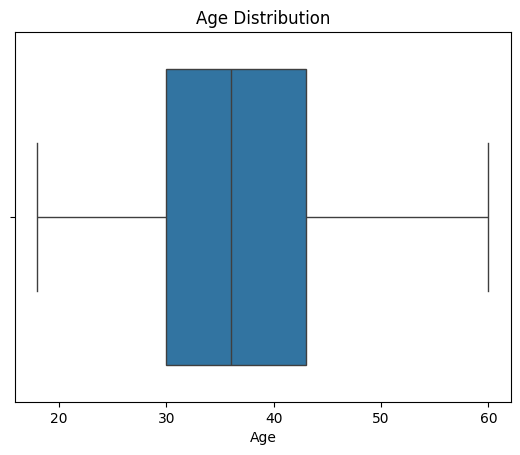

In [42]:
sns.boxplot(data=df_clean, x="Age")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()

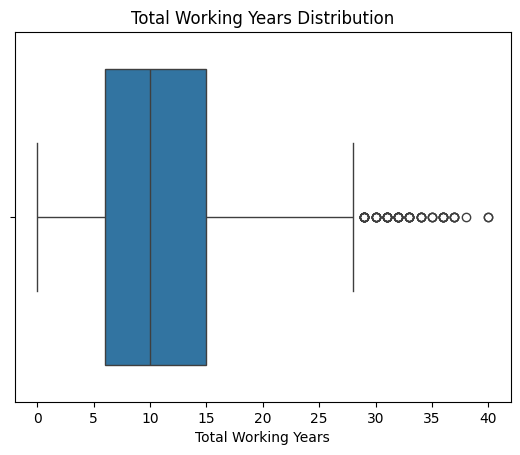

In [43]:
sns.boxplot(data=df_clean, x="TotalWorkingYears")

plt.title("Total Working Years Distribution")
plt.xlabel("Total Working Years")
plt.show()

In [44]:
invalid_years = df_clean[
    df_clean["YearsAtCompany"] > df_clean["TotalWorkingYears"]
]

print("Invalid records:", len(invalid_years))

Invalid records: 0


In [45]:
department_rate = pd.crosstab(
    df_clean["Department"],
    df_clean["Attrition"],
    normalize="index"
) * 100

department_rate

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


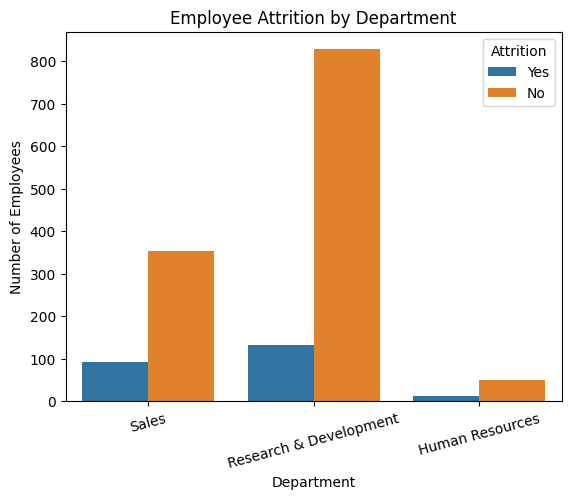

In [46]:
sns.countplot(
    data=df_clean,
    x="Department",
    hue="Attrition"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=15)

plt.show()

In [48]:
overtime_rate = pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"],
    normalize="index"
) * 100

overtime_rate

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


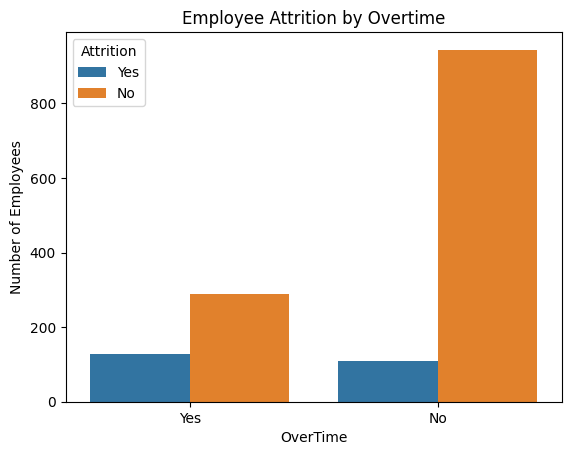

In [49]:
sns.countplot(
    data=df_clean,
    x="OverTime",
    hue="Attrition"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Number of Employees")

plt.show()

In [51]:
df_clean.groupby("Attrition")["MonthlyIncome"].mean()

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64

In [52]:
df_clean["SalaryGroup"] = pd.qcut(
    df_clean["MonthlyIncome"],
    4,
    labels=["Low", "Medium", "High", "Very High"]
)

In [53]:
df_clean["SalaryGroup"].value_counts().sort_index()

SalaryGroup
Low          369
Medium       366
High         367
Very High    368
Name: count, dtype: int64

In [54]:
salary_rate = pd.crosstab(
    df_clean["SalaryGroup"],
    df_clean["Attrition"],
    normalize="index"
) * 100

salary_rate

Attrition,No,Yes
SalaryGroup,,
Low,70.731707,29.268293
Medium,85.792350,14.207650
High,89.373297,10.626703
Very High,89.673913,10.326087


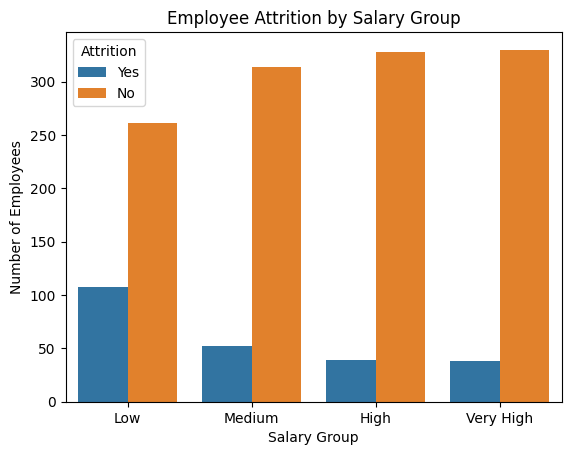

In [55]:
sns.countplot(
    data=df_clean,
    x="SalaryGroup",
    hue="Attrition"
)

plt.title("Employee Attrition by Salary Group")
plt.xlabel("Salary Group")
plt.ylabel("Number of Employees")

plt.show()

In [56]:
satisfaction_rate = pd.crosstab(
    df_clean["JobSatisfaction"],
    df_clean["Attrition"],
    normalize="index"
) * 100

satisfaction_rate

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


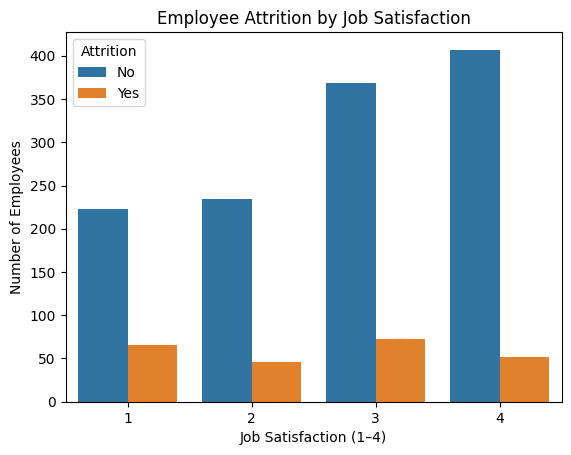

In [57]:
sns.countplot(
    data=df_clean,
    x="JobSatisfaction",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction (1–4)")
plt.ylabel("Number of Employees")

plt.show()

In [58]:
worklife_rate = pd.crosstab(
    df_clean["WorkLifeBalance"],
    df_clean["Attrition"],
    normalize="index"
) * 100

worklife_rate

Attrition,No,Yes
WorkLifeBalance,,
1,68.750000,31.250000
2,83.139535,16.860465
3,85.778275,14.221725
4,82.352941,17.647059


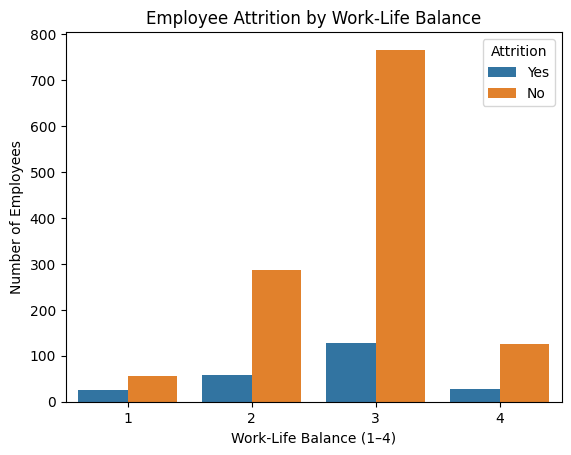

In [59]:
sns.countplot(
    data=df_clean,
    x="WorkLifeBalance",
    hue="Attrition"
)

plt.title("Employee Attrition by Work-Life Balance")
plt.xlabel("Work-Life Balance (1–4)")
plt.ylabel("Number of Employees")

plt.show()

In [60]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[0, 25, 35, 45, 100],
    labels=["<=25", "26-35", "36-45", "46+"]
)

df_clean["AgeGroup"].value_counts()

AgeGroup
26-35    606
36-45    468
46+      273
<=25     123
Name: count, dtype: int64

In [61]:
age_attrition = pd.crosstab(
    df_clean["AgeGroup"],
    df_clean["Attrition"],
    normalize="index"
) * 100

age_attrition

Attrition,No,Yes
AgeGroup,,
<=25,64.227642,35.772358
26-35,80.858086,19.141914
36-45,90.811966,9.188034
46+,87.545788,12.454212


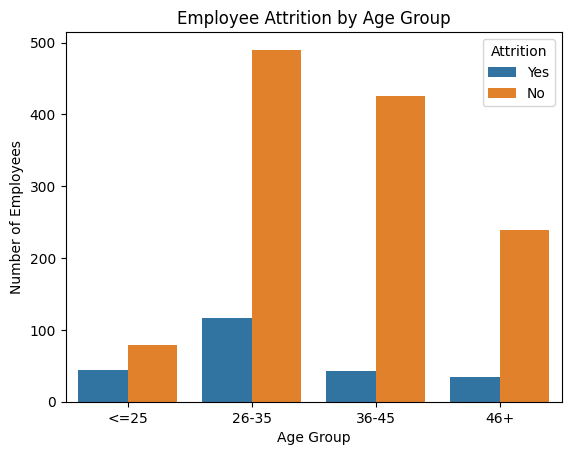

In [62]:
sns.countplot(
    data=df_clean,
    x="AgeGroup",
    hue="Attrition"
)

plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.show()

In [63]:
role_attrition = pd.crosstab(
    df_clean["JobRole"],
    df_clean["Attrition"],
    normalize="index"
) * 100

role_attrition

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.129771,6.870229
Human Resources,76.923077,23.076923
Laboratory Technician,76.061776,23.938224
Manager,95.098039,4.901961
Manufacturing Director,93.103448,6.896552
Research Director,97.500000,2.500000
Research Scientist,83.904110,16.095890
Sales Executive,82.515337,17.484663
Sales Representative,60.240964,39.759036


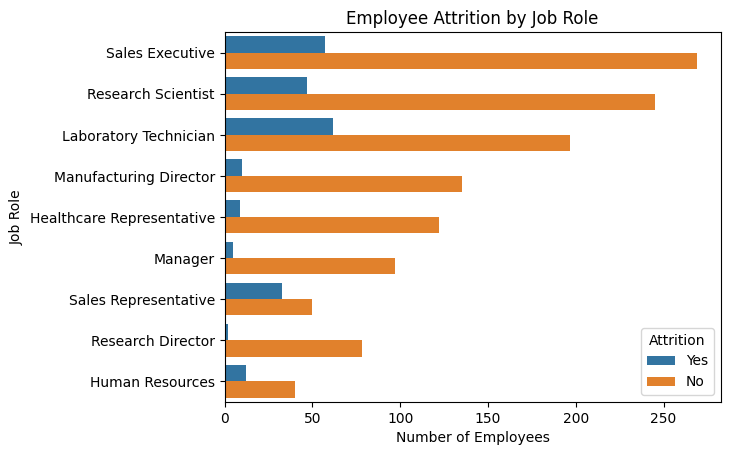

In [64]:
sns.countplot(
    data=df_clean,
    y="JobRole",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

plt.show()

In [65]:
travel_attrition = pd.crosstab(
    df_clean["BusinessTravel"],
    df_clean["Attrition"],
    normalize="index"
) * 100

travel_attrition

Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.000000,8.000000
Travel_Frequently,75.090253,24.909747
Travel_Rarely,85.043145,14.956855


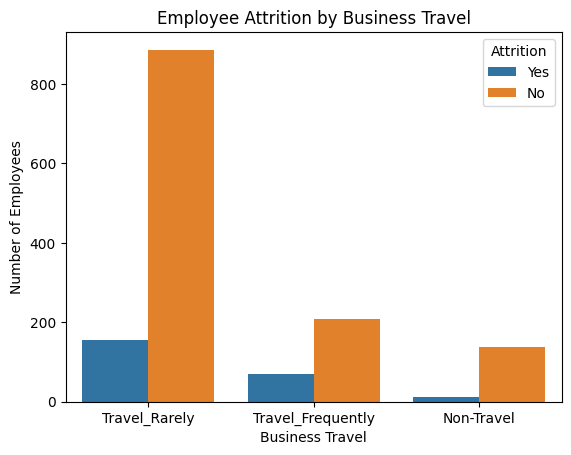

In [66]:
sns.countplot(
    data=df_clean,
    x="BusinessTravel",
    hue="Attrition"
)

plt.title("Employee Attrition by Business Travel")
plt.xlabel("Business Travel")
plt.ylabel("Number of Employees")

plt.show()

In [67]:
marital_attrition = pd.crosstab(
    df_clean["MaritalStatus"],
    df_clean["Attrition"],
    normalize="index"
) * 100

marital_attrition

Attrition,No,Yes
MaritalStatus,,
Divorced,89.908257,10.091743
Married,87.518574,12.481426
Single,74.468085,25.531915


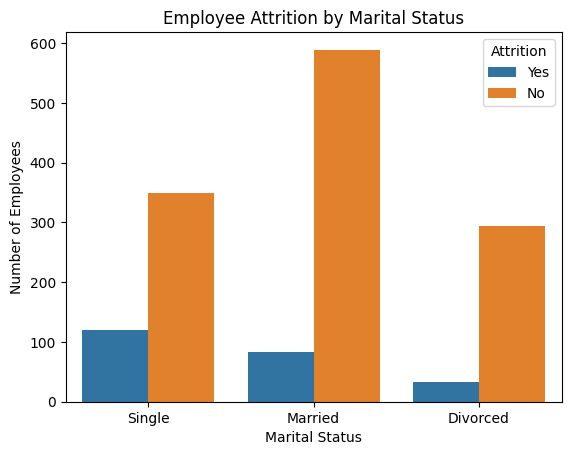

In [68]:
sns.countplot(
    data=df_clean,
    x="MaritalStatus",
    hue="Attrition"
)

plt.title("Employee Attrition by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Employees")

plt.show()

In [69]:
df_clean.groupby("Attrition")["Age"].mean()

Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64

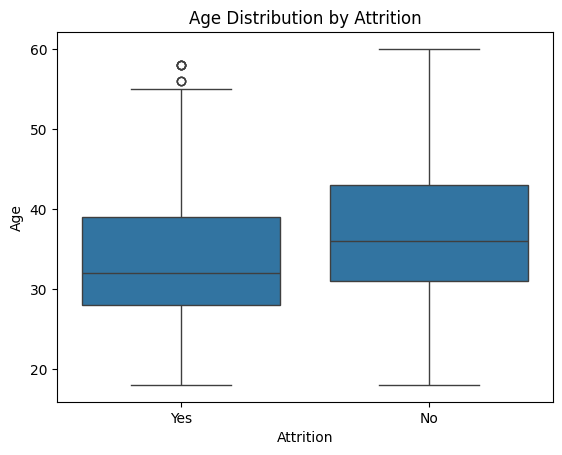

In [70]:
sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="Age"
)

plt.title("Age Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")

plt.show()

In [71]:
df_clean.groupby("Attrition")["MonthlyIncome"].mean()

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64

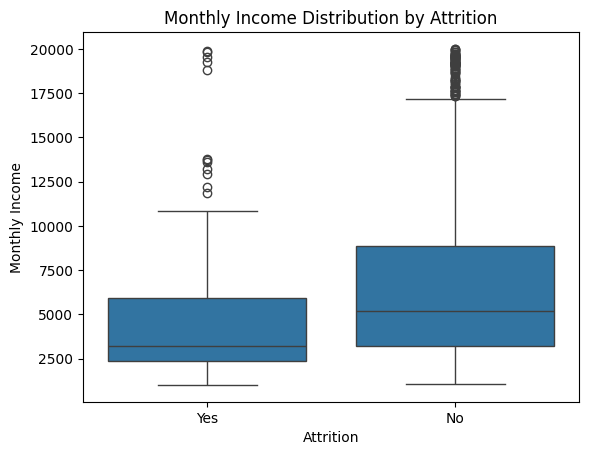

In [72]:
sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

In [73]:
df_clean.groupby("Attrition")["TotalWorkingYears"].mean()

Attrition
No     11.862936
Yes     8.244726
Name: TotalWorkingYears, dtype: float64

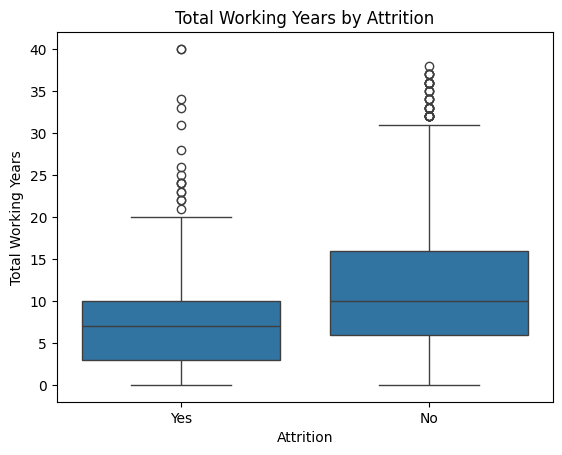

In [74]:
sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="TotalWorkingYears"
)

plt.title("Total Working Years by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Total Working Years")

plt.show()

In [75]:
df_clean.groupby("Attrition")["YearsAtCompany"].mean()

Attrition
No     7.369019
Yes    5.130802
Name: YearsAtCompany, dtype: float64

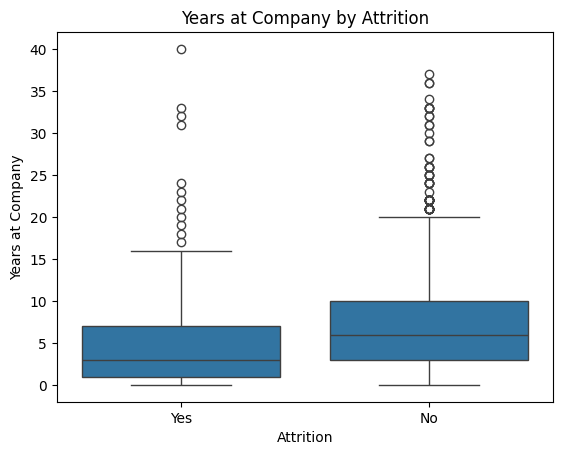

In [76]:
sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsAtCompany"
)

plt.title("Years at Company by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

In [77]:
df_clean.groupby("Attrition")["YearsInCurrentRole"].mean()

Attrition
No     4.484185
Yes    2.902954
Name: YearsInCurrentRole, dtype: float64

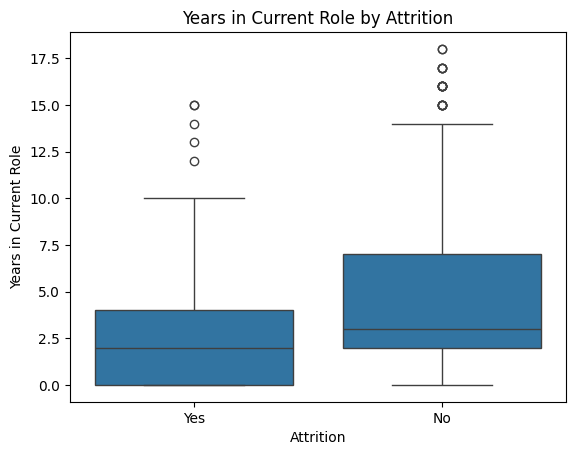

In [78]:
sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsInCurrentRole"
)

plt.title("Years in Current Role by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years in Current Role")

plt.show()

In [79]:
df_clean.groupby("Attrition")["YearsWithCurrManager"].mean()

Attrition
No     4.367397
Yes    2.852321
Name: YearsWithCurrManager, dtype: float64

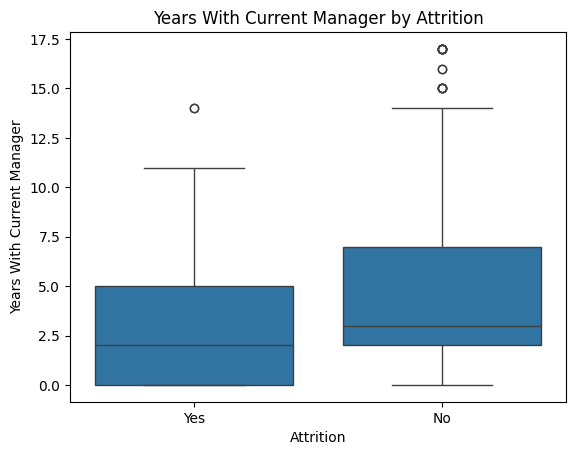

In [80]:
sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsWithCurrManager"
)

plt.title("Years With Current Manager by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years With Current Manager")

plt.show()

In [81]:
df_clean.groupby("Attrition")[[
    "Age",
    "MonthlyIncome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager"
]].mean()

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsWithCurrManager
Attrition,,,,,,
No,37.561233,6832.739659,11.862936,7.369019,4.484185,4.367397
Yes,33.607595,4787.092827,8.244726,5.130802,2.902954,2.852321


In [82]:
pd.crosstab(
    [df_clean["AgeGroup"], df_clean["OverTime"]],
    df_clean["Attrition"],
    normalize="index"
) * 100

Attrition                 No        Yes
AgeGroup OverTime                      
<=25     No        77.380952  22.619048
         Yes       35.897436  64.102564
26-35    No        87.919463  12.080537
         Yes       61.006289  38.993711
36-45    No        93.993994   6.006006
         Yes       82.962963  17.037037
46+      No        91.052632   8.947368
         Yes       79.518072  20.481928

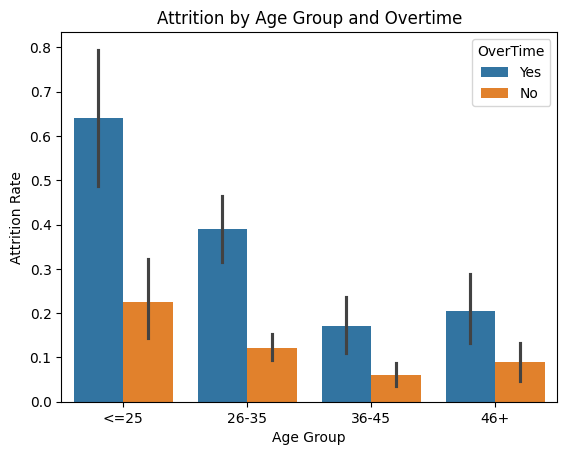

In [83]:
sns.barplot(
    data=df_clean,
    x="AgeGroup",
    y=df_clean["Attrition"].eq("Yes"),
    hue="OverTime"
)

plt.title("Attrition by Age Group and Overtime")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate")
plt.show()

In [85]:
pd.crosstab(
    [df_clean["SalaryGroup"], df_clean["OverTime"]],
    df_clean["Attrition"],
    normalize="index"
) * 100

Attrition                    No        Yes
SalaryGroup OverTime                      
Low         No        82.509506  17.490494
            Yes       41.509434  58.490566
Medium      No        90.000000  10.000000
            Yes       73.958333  26.041667
High        No        93.023256   6.976744
            Yes       80.733945  19.266055
Very High   No        92.775665   7.224335
            Yes       81.904762  18.095238

In [86]:
pd.crosstab(
    [df_clean["JobSatisfaction"], df_clean["OverTime"]],
    df_clean["Attrition"],
    normalize="index"
) * 100

Attrition                        No        Yes
JobSatisfaction OverTime                      
1               No        82.439024  17.560976
                Yes       64.285714  35.714286
2               No        90.521327   9.478673
                Yes       62.318841  37.681159
3               No        90.031153   9.968847
                Yes       66.115702  33.884298
4               No        93.059937   6.940063
                Yes       78.873239  21.126761

In [87]:
total_employees = len(df_clean)

print("Total Employees:", total_employees)

Total Employees: 1470


In [88]:
employees_left = (df_clean["Attrition"] == "Yes").sum()

print("Employees Who Left:", employees_left)

Employees Who Left: 237


In [89]:
employees_stayed = (df_clean["Attrition"] == "No").sum()

print("Employees Who Stayed:", employees_stayed)

Employees Who Stayed: 1233


In [90]:
attrition_rate = (employees_left / total_employees) * 100

print("Attrition Rate:", round(attrition_rate, 2), "%")

Attrition Rate: 16.12 %


In [91]:
average_age = df_clean["Age"].mean()

print("Average Employee Age:", round(average_age, 2))

Average Employee Age: 36.92


In [92]:
average_income = df_clean["MonthlyIncome"].mean()

print("Average Monthly Income:", round(average_income, 2))

Average Monthly Income: 6502.93


In [93]:
average_working_years = df_clean["TotalWorkingYears"].mean()

print("Average Total Working Years:", round(average_working_years, 2))

Average Total Working Years: 11.28


In [94]:
average_tenure = df_clean["YearsAtCompany"].mean()

print("Average Years at Company:", round(average_tenure, 2))

Average Years at Company: 7.01


In [95]:
average_satisfaction = df_clean["JobSatisfaction"].mean()

print("Average Job Satisfaction:", round(average_satisfaction, 2))

Average Job Satisfaction: 2.73


In [96]:
average_worklife = df_clean["WorkLifeBalance"].mean()

print("Average Work-Life Balance:", round(average_worklife, 2))

Average Work-Life Balance: 2.76


In [97]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Employees",
        "Employees Who Left",
        "Employees Who Stayed",
        "Attrition Rate (%)",
        "Average Age",
        "Average Monthly Income",
        "Average Total Working Years",
        "Average Years at Company",
        "Average Job Satisfaction",
        "Average Work-Life Balance"
    ],
    "Value": [
        total_employees,
        employees_left,
        employees_stayed,
        round(attrition_rate, 2),
        round(average_age, 2),
        round(average_income, 2),
        round(average_working_years, 2),
        round(average_tenure, 2),
        round(average_satisfaction, 2),
        round(average_worklife, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Employees,1470.00
1,Employees Who Left,237.00
2,Employees Who Stayed,1233.00
3,Attrition Rate (%),16.12
4,Average Age,36.92
5,Average Monthly Income,6502.93
6,Average Total Working Years,11.28
7,Average Years at Company,7.01
8,Average Job Satisfaction,2.73
9,Average Work-Life Balance,2.76


In [98]:
pd.crosstab(
    [df_clean["JobRole"], df_clean["OverTime"]],
    df_clean["Attrition"],
    normalize="index"
) * 100

Attrition                                  No        Yes
JobRole                   OverTime                      
Healthcare Representative No        92.553191   7.446809
                          Yes       94.594595   5.405405
Human Resources           No        82.051282  17.948718
                          Yes       61.538462  38.461538
Laboratory Technician     No        84.263959  15.736041
                          Yes       50.000000  50.000000
Manager                   No        98.666667   1.333333
                          Yes       85.185185  14.814815
Manufacturing Director    No        94.339623   5.660377
                          Yes       89.743590  10.256410
Research Director         No        98.245614   1.754386
                          Yes       95.652174   4.347826
Research Scientist        No        92.820513   7.179487
                          Yes       65.979381  34.020619
Sales Executive           No        88.793103  11.206897
                          Yes       67.021277  32.978723
Sales Representative      No        71.186441  28.813559
                          Yes       33.333333  66.666667

In [99]:
pd.crosstab(
    df_clean["JobRole"],
    df_clean["OverTime"]
)

OverTime,No,Yes
JobRole,,
Healthcare Representative,94,37
Human Resources,39,13
Laboratory Technician,197,62
Manager,75,27
Manufacturing Director,106,39
Research Director,57,23
Research Scientist,195,97
Sales Executive,232,94
Sales Representative,59,24


In [100]:
pd.crosstab(
    df_clean["SalaryGroup"],
    df_clean["OverTime"]
)

OverTime,No,Yes
SalaryGroup,,
Low,263,106
Medium,270,96
High,258,109
Very High,263,105


In [101]:
df_clean.to_csv(
    "employee_attrition_tableau.csv",
    index=False
)